# Babuinos en conflicto — solución concurrente en Java

**Programación Concurrente — UNLaM — Actividad Práctica: Comunicación y Sincronización**

## El problema

> En una reserva natural sudafricana existe un profundo cañón. Los babuinos del lugar utilizan una cuerda
> atada en ambos extremos para cruzar de un lado al otro. La cuerda es lo suficientemente fuerte como para
> soportar a **cinco (5) babuinos colgados al mismo tiempo**; de superar esa cantidad la cuerda se romperá.
> Por razones desconocidas, si **dos babuinos que van en direcciones opuestas** se encuentran en medio del
> cruce, se ponen a pelear hasta que alguno cae al vacío.
>
> Desarrolle un programa que represente el cruce de los babuinos **garantizando que ninguno muera**.

## Qué significa "que ninguno muera"

El enunciado describe dos formas de morir, y cada una es un **invariante** que el programa debe sostener en
todo momento, no "casi siempre":

| Causa de muerte | Invariante a garantizar |
|---|---|
| La cuerda se rompe por exceso de peso | `cantidad_de_babuinos_colgados <= 5` |
| Dos babuinos se cruzan de frente y pelean | todos los babuinos colgados van en **el mismo sentido** |

Hay además un tercer requisito que el enunciado no menciona pero que un programa concurrente correcto sí
debe cumplir: **que todos lleguen al otro lado alguna vez**. Un programa que dejara cruzar sólo a los del
Este sería trivialmente seguro —ningún accidente— pero los babuinos del Oeste esperarían para siempre. Eso
se llama **inanición** (*starvation*) y es un error de diseño tan real como una pelea. Lo vamos a medir y a
corregir explícitamente en la sección 9.

Entonces las tres propiedades que buscamos son las tres propiedades clásicas de la concurrencia:

- **Seguridad** (*safety*): nunca pasa algo malo → nunca se rompe la cuerda ni hay dos sentidos a la vez.
- **Vivacidad** (*liveness*): eventualmente pasa algo bueno → todo babuino que llega termina cruzando.
- **Ausencia de interbloqueo** (*deadlock*): nunca se llega a un estado donde todos esperan a todos.

## 1. Del enunciado a las primitivas de concurrencia

Antes de escribir código hay que decidir qué es cada cosa del dominio en términos concurrentes. Éste es el
diseño completo:

| Elemento del enunciado | Abstracción concurrente | Primitiva de Java |
|---|---|---|
| Cada babuino | **Hilo** (flujo de ejecución independiente dentro del mismo proceso) | `Thread` + `Runnable` |
| La cuerda | **Recurso compartido** con reglas de acceso | un **monitor**: clase con estado privado |
| Permiso para colgarse / soltarse | **Sección crítica** de entrada y salida | `ReentrantLock` (exclusión mutua) |
| "Espero mi turno colgado de la rama" | **Espera pasiva** sobre una condición | `Condition.await()` / `signalAll()` |
| Límite de 5 colgados | Recurso con cupo | contador dentro del monitor (o `Semaphore(5)`) |
| Cruzar el cañón (tarda un rato) | Trabajo **fuera** de la sección crítica | `Thread.sleep(...)` |
| Contar quién cruzó y avisar por consola | **Comunicación** entre hilos | `BlockingQueue` (productor–consumidor) |
| Auditar que no hubo muertes | Lectura/escritura sin bloqueo | variables **atómicas** (`AtomicInteger`) |
| Largar a todos juntos | **Sincronización de arranque** (barrera) | `CountDownLatch` |
| Esperar a que termine la migración | **Sincronización de terminación** | `Thread.join()` |

Dos decisiones de fondo que conviene explicitar:

**1. Memoria compartida, no paso de mensajes (para la cuerda).** Todos los hilos babuino corren dentro de
la misma JVM y ven el mismo objeto `Cuerda`. La coordinación se hace **modificando estado compartido bajo
exclusión mutua**. La alternativa —cada babuino como proceso separado mandándose mensajes— sería otro
modelo válido (el de Erlang o el de los canales de Go), pero acá el recurso es físico y único: modelarlo
como un objeto con estado es lo natural.

**2. Paso de mensajes, sí, para la bitácora.** La salida por consola también es un recurso compartido. En
vez de que cada babuino haga `System.out.println` (lo que entrelaza líneas y obliga a sincronizar `stdout`),
cada uno **encola un evento** y un único hilo lo imprime. Ahí sí usamos comunicación por mensajes.

La regla que guía todo el diseño es: **lo que no se comparte no se sincroniza**. El estado privado de cada
babuino (su nombre, su sentido, cuánto esperó) vive en su propio objeto y nadie más lo escribe; sólo se
protege lo que efectivamente se comparte.

## 2. Andamiaje: cómo corremos Java desde el cuaderno

El cuaderno usa el núcleo de Python, así que Python cumple acá el rol de **guion de build y de banco de
pruebas**: escribe el archivo `.java`, lo compila con `javac` y lo ejecuta con `java` como un proceso
aparte, capturando su salida. Toda la concurrencia ocurre dentro de la JVM; Python sólo la lanza y lee lo
que imprime.

Requisito: tener el JDK instalado (`javac -version` desde la terminal). El código usa sólo la biblioteca
estándar, no hace falta ninguna dependencia.

In [1]:
import pathlib
import statistics
import subprocess

DIR      = pathlib.Path("java_babuinos")      # acá vive el código Java generado
FUENTE_J = DIR / "Babuinos.java"
BUILD    = DIR / "build"                       # acá van los .class compilados
DIR.mkdir(exist_ok=True)


def compilar():
    # -encoding UTF-8: los comentarios del fuente tienen acentos.
    proc = subprocess.run(["javac", "-encoding", "UTF-8", "-d", str(BUILD), str(FUENTE_J)],
                          capture_output=True, text=True, encoding="utf-8", errors="replace")
    if proc.returncode != 0:
        raise RuntimeError("Error de compilación:\n" + proc.stdout + proc.stderr)
    return "Compilación correcta: " + str(FUENTE_J)


def correr(n_este=6, n_oeste=5, max_tanda=5, semilla=42, verbose=True, ingenua=False):
    # Lanza la JVM como proceso hijo y devuelve todo lo que el programa imprimió.
    args = [str(n_este), str(n_oeste), str(max_tanda), str(semilla),
            "1" if verbose else "0", "1" if ingenua else "0"]
    proc = subprocess.run(["java", "-cp", str(BUILD), "Babuinos", *args],
                          capture_output=True, text=True, encoding="utf-8", errors="replace")
    if proc.returncode != 0:
        raise RuntimeError("Error de ejecución:\n" + proc.stdout + proc.stderr)
    return proc.stdout


def metricas(salida):
    # El programa Java termina imprimiendo una línea "##RESULTADO clave=valor ..." fácil de parsear.
    linea = [l for l in salida.splitlines() if l.startswith("##RESULTADO")][-1]
    datos = {}
    for par in linea.split()[1:]:
        clave, valor = par.split("=")
        datos[clave] = float(valor) if "." in valor else int(valor)
    return datos


version = subprocess.run(["javac", "-version"], capture_output=True, text=True)
print("JDK disponible:", (version.stdout + version.stderr).strip())

JDK disponible: [0.021s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.021s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
javac 21.0.12


## 3. El programa Java, por partes

Vamos a armar un único archivo `Babuinos.java` juntando bloques que se definen de a uno, cada uno precedido
por su explicación. Guardamos cada bloque en el diccionario `FUENTE` y al final los concatenamos en el orden
de la lista `ORDEN`. Así cada celda se puede volver a ejecutar sin duplicar código.

La arquitectura es ésta:

```
                 +-------------------+
  hilo babuino ->|                   |
  hilo babuino ->|   Cuerda          |  <- monitor: cerrojo + 2 variables de condición
  hilo babuino ->|  (recurso         |
  hilo babuino ->|   compartido)     |
                 +-------------------+
        |                                  ^
        | eventos (cola bloqueante)        | auditoría (variables atómicas)
        v                                  |
   +----------+                     +--------------+
   | Bitácora |                     | Verificador  |
   | 1 hilo   |                     | (invariantes)|
   +----------+                     +--------------+
```

In [2]:
FUENTE = {}

ORDEN = ["encabezado", "interfaz", "ingenua", "segura", "verificador", "bitacora", "babuino", "principal"]

### 3.1 Encabezado

Todo lo que usamos vive en `java.util.concurrent`, el paquete de utilidades de concurrencia de Java (el
*java.util.concurrent* de Doug Lea). Es deliberado: **no usamos `synchronized` / `wait()` / `notify()`**,
que son la sincronización "de bajo nivel" del lenguaje, sino `ReentrantLock` y `Condition`, que son
equivalentes pero permiten algo que acá es central: **varias colas de espera sobre un mismo cerrojo** (una
por sentido de cruce). Con `synchronized` hay una única cola de espera por objeto, y habría que despertar a
todos para que casi todos vuelvan a dormirse.

In [3]:
FUENTE["encabezado"] = r'''
// =====================================================================================
//  Babuinos en conflicto  -  Programación Concurrente (UNLaM)
//  Una cuerda sobre un cañón: hasta 5 babuinos colgados y todos en el mismo sentido.
// =====================================================================================
import java.util.ArrayList;
import java.util.List;
import java.util.Locale;
import java.util.Random;
import java.util.concurrent.BlockingQueue;
import java.util.concurrent.CountDownLatch;
import java.util.concurrent.LinkedBlockingQueue;
import java.util.concurrent.Semaphore;
import java.util.concurrent.atomic.AtomicInteger;
import java.util.concurrent.atomic.AtomicIntegerArray;
import java.util.concurrent.locks.Condition;
import java.util.concurrent.locks.ReentrantLock;
'''

### 3.2 El contrato del recurso compartido

Un babuino sólo hace dos cosas con la cuerda: **subirse** (y quedarse esperando si no puede) y **bajarse**.
Ese par de operaciones es el **protocolo de entrada y salida de la sección crítica**.

Definirlo como una interfaz nos permite después usar dos implementaciones distintas y compararlas
corriendo exactamente el mismo experimento: una ingenua (que mata babuinos) y una correcta.

In [4]:
FUENTE["interfaz"] = r'''
/** Contrato del recurso compartido: subirse y bajarse de la cuerda. */
interface Cuerda {
    /** Protocolo de ENTRADA: bloquea al hilo hasta que sea seguro colgarse. */
    void subirse(int direccion) throws InterruptedException;

    /** Protocolo de SALIDA: libera el lugar y, si corresponde, despierta a quien esperaba. */
    void bajarse(int direccion);

    String descripcion();

    /** Cantidad de "tandas" (grupos consecutivos en un mismo sentido). -1 si no aplica. */
    int tandas();
}
'''

### 3.3 Primer intento (incorrecto): sólo un semáforo de capacidad

Es el error típico al leer el enunciado rápido: "la cuerda aguanta 5 → uso un semáforo con 5 permisos".

Un **semáforo contador** es exactamente eso, un contador de permisos con dos operaciones atómicas:
`acquire()` (la *P* de Dijkstra: descontar un permiso o bloquearse si no hay) y `release()` (la *V*:
devolver el permiso y despertar a alguien). Resuelve *perfectamente* la primera mitad del problema: nunca
va a haber seis babuinos colgados.

Pero **no resuelve la segunda**: el semáforo no sabe nada de sentidos. Dos babuinos que vienen de orillas
opuestas piden permisos distintos, los dos los consiguen, y se encuentran en el medio. Esto es una
**condición de carrera**: el resultado depende de la intercalación temporal que elija el planificador del
sistema operativo, y por eso a veces "anda" y a veces no.

Lo dejamos escrito a propósito para ejecutarlo en la sección 6 y **ver morir babuinos**.

In [5]:
FUENTE["ingenua"] = r'''
/**
 * Versión INGENUA (incorrecta a propósito).
 * Respeta el límite físico de 5 babuinos con un semáforo contador, pero no controla
 * el sentido del cruce, así que permite encuentros de frente: hay peleas.
 */
class CuerdaIngenua implements Cuerda {
    private final Semaphore lugares;

    CuerdaIngenua(int capacidad) {
        // true = semáforo "justo": respeta el orden de llegada (FIFO) de los bloqueados.
        this.lugares = new Semaphore(capacidad, true);
    }

    public void subirse(int direccion) throws InterruptedException {
        lugares.acquire();          // P: toma un permiso... sin mirar para qué lado va el otro
    }

    public void bajarse(int direccion) {
        lugares.release();          // V: devuelve el permiso
    }

    public String descripcion() { return "INGENUA (solo semaforo de capacidad)"; }
    public int tandas() { return -1; }
}
'''

### 3.4 La solución: la cuerda como **monitor**

Un **monitor** es la abstracción de sincronización de más alto nivel de las tres clásicas (semáforos,
monitores, paso de mensajes): un objeto que encapsula estado compartido, garantiza que **a lo sumo un hilo
esté ejecutando sus métodos a la vez** (exclusión mutua) y ofrece **variables de condición** para que un
hilo se duerma adentro hasta que el estado le convenga.

En Java 5+ un monitor se arma con `ReentrantLock` (el cerrojo) + tantos `Condition` como colas de espera se
necesiten. Acá hay dos colas, una por sentido:

```
                        cerrojo (ReentrantLock)
                                 |
              +------------------+------------------+
              |                                     |
      esperaCruce[ESTE]                     esperaCruce[OESTE]
      (babuinos que quieren ir              (babuinos que quieren ir
       Este -> Oeste)                        Oeste -> Este)
```

**El estado compartido** que protege el cerrojo:

| Variable | Significado |
|---|---|
| `enLaCuerda` | cuántos están colgados ahora |
| `sentidoActivo` | sentido de la tanda en curso (`LIBRE` si la cuerda está vacía) |
| `esperando[2]` | cuántos esperan de cada lado (hace falta para decidir el turno) |
| `consecutivos` | cuántos entraron seguidos en la tanda actual |

**La condición de entrada** (`puedeSubir`) es la traducción literal de los invariantes:

```java
if (enLaCuerda >= capacidad)                             -> NO  // se rompería la cuerda
if (sentidoActivo != LIBRE && sentidoActivo != mi_sentido) -> NO  // habría pelea
if (ya pasaron maxTanda seguidos && enfrente hay cola)   -> NO  // le cedo el turno al otro lado
```

Tres detalles finos que son los que hacen que esto sea correcto:

**a) `while`, no `if`.** La espera se escribe siempre así:

```java
while (!puedeSubir(direccion)) esperaCruce[direccion].await();
```

Los monitores de Java tienen **semántica Mesa**: cuando alguien hace `signal`, el hilo despertado **no
recibe el cerrojo de inmediato**, sino que vuelve a competir por él. Entre el aviso y el momento en que
realmente entra, otro hilo pudo haber cambiado el estado. Por eso la condición se **revuelve a verificar**
al despertar. Con `if` en lugar de `while`, un babuino podría colgarse de una cuerda que ya se llenó: es
uno de los bugs de concurrencia más clásicos que existen.

**b) `await()` libera el cerrojo.** Dormirse adentro del monitor no bloquea a los demás: `await()` suelta el
cerrojo atómicamente y lo vuelve a tomar al despertar. Si no fuera así, el primer babuino que esperara
dejaría a todo el resto afuera para siempre (interbloqueo).

**c) La cesión de turno evita la inanición.** Si sólo pidiéramos "mismo sentido y menos de 5", un flujo
constante de babuinos del Este haría que la cuerda **nunca se vacíe**, y los del Oeste esperarían
indefinidamente. `maxTanda` limita cuántos entran seguidos **cuando hay cola del otro lado**; y cuando la
cuerda queda vacía, `bajarse` **reserva** el sentido para el lado que estaba esperando. Con eso la espera
queda acotada: ningún babuino puede ser postergado más que un par de tandas. Es el mismo problema y la
misma solución que en lectores–escritores con prioridad alternada.

> `maxTanda = 0` desactiva la cesión de turno. No es un modo "roto" en cuanto a seguridad —sigue sin haber
> muertes— pero produce inanición, y lo vamos a usar en la sección 9 para medirla.

In [6]:
FUENTE["segura"] = r'''
/**
 * Versión SEGURA: la cuerda como MONITOR.
 *   - un cerrojo (exclusión mutua sobre el estado),
 *   - dos variables de condición (una cola de espera por sentido).
 *
 * Invariantes garantizados en todo momento:
 *   I1)  0 <= enLaCuerda <= capacidad                (la cuerda no se rompe)
 *   I2)  enLaCuerda > 0  =>  todos van en sentidoActivo   (no hay peleas)
 */
class CuerdaSegura implements Cuerda {
    private static final int LIBRE = -1;

    private final ReentrantLock cerrojo = new ReentrantLock(true);   // true = orden FIFO entre los que compiten
    private final Condition[] esperaCruce = { null, null };          // una cola de espera por sentido
    private final int capacidad;
    private final int maxTanda;            // cuántos entran seguidos si el otro lado espera; 0 = sin límite

    // ---- ESTADO COMPARTIDO: sólo se toca con el cerrojo tomado ----
    private int enLaCuerda = 0;
    private int sentidoActivo = LIBRE;
    private final int[] esperando = new int[2];
    private int consecutivos = 0;
    private int tandas = 0;

    CuerdaSegura(int capacidad, int maxTanda) {
        this.capacidad = capacidad;
        this.maxTanda = maxTanda;
        this.esperaCruce[0] = cerrojo.newCondition();
        this.esperaCruce[1] = cerrojo.newCondition();
    }

    /** PROTOCOLO DE ENTRADA. */
    public void subirse(int direccion) throws InterruptedException {
        cerrojo.lock();
        try {
            esperando[direccion]++;                       // me anoto en la cola de mi sentido
            while (!puedeSubir(direccion)) {
                esperaCruce[direccion].await();           // espera PASIVA: suelta el cerrojo y duerme
            }                                             // while (no if): semántica Mesa
            esperando[direccion]--;
            if (enLaCuerda == 0) tandas++;                // arranca una tanda nueva
            enLaCuerda++;
            consecutivos++;
            sentidoActivo = direccion;
        } finally {
            cerrojo.unlock();                             // en finally: si algo falla, el cerrojo se libera igual
        }
    }

    /** La condición de entrada = los invariantes + la regla anti-inanición. */
    private boolean puedeSubir(int direccion) {
        if (enLaCuerda >= capacidad) return false;                                  // I1
        if (sentidoActivo != LIBRE && sentidoActivo != direccion) return false;     // I2
        if (maxTanda > 0 && consecutivos >= maxTanda && esperando[1 - direccion] > 0) {
            return false;                                                           // cedo el turno
        }
        return true;
    }

    /** PROTOCOLO DE SALIDA. */
    public void bajarse(int direccion) {
        cerrojo.lock();
        try {
            enLaCuerda--;
            if (enLaCuerda == 0) {
                // La cuerda quedó vacía: es el único momento en que se puede cambiar de sentido.
                consecutivos = 0;
                int otro = 1 - direccion;
                if (esperando[otro] > 0) {
                    sentidoActivo = otro;                 // RESERVA el turno para el lado que esperaba
                    esperaCruce[otro].signalAll();
                } else {
                    sentidoActivo = LIBRE;
                    esperaCruce[direccion].signalAll();
                }
            } else {
                // Quedó un lugar libre en la tanda actual: sólo pueden entrar los de mi mismo sentido.
                esperaCruce[direccion].signalAll();
            }
        } finally {
            cerrojo.unlock();
        }
    }

    public String descripcion() { return "SEGURA (monitor con variables de condicion)"; }

    /** Lectura de estado compartido: también va bajo cerrojo. */
    public int tandas() { cerrojo.lock(); try { return tandas; } finally { cerrojo.unlock(); } }
}
'''

### 3.5 El verificador: auditar los invariantes desde afuera

Que el monitor esté bien escrito es una cosa; **demostrarlo con una corrida** es otra. El `Verificador` es
un observador independiente: cada babuino le avisa cuando **efectivamente** está colgado y cuando se baja,
y él lleva la cuenta por sentido. Si alguna vez detecta que hay colgados de los dos lados a la vez, registra
una **pelea**; si detecta más de cinco, una **rotura**.

Es deliberado que no comparta el cerrojo del monitor: si usara la misma exclusión mutua, estaría "haciendo
trampa" (verificaría el estado que el monitor cree tener, no el real). Usa **variables atómicas**
(`AtomicInteger`, `AtomicIntegerArray`), que ofrecen operaciones *lock-free* implementadas con la
instrucción **compare-and-swap** del procesador: `incrementAndGet()` es indivisible sin necesidad de
bloquear a nadie.

Ojo con lo que este tipo de auditoría puede y no puede: puede **encontrar** violaciones (y en la versión
ingenua las encuentra enseguida), pero no puede *probar* que no existan. La ausencia de muertes en una
corrida es evidencia; la garantía viene del razonamiento sobre los invariantes del monitor.

In [7]:
FUENTE["verificador"] = r'''
/**
 * Auditor externo al monitor: comprueba los invariantes con variables ATÓMICAS
 * (operaciones lock-free basadas en compare-and-swap).
 */
class Verificador {
    private final AtomicIntegerArray colgados = new AtomicIntegerArray(2);   // colgados por sentido
    private final AtomicInteger maxSimultaneos = new AtomicInteger();
    private final AtomicInteger peleas  = new AtomicInteger();               // violaciones de I2
    private final AtomicInteger roturas = new AtomicInteger();               // violaciones de I1
    private final int capacidad;

    Verificador(int capacidad) { this.capacidad = capacidad; }

    /** Lo llama el babuino cuando ya está colgado de la cuerda. */
    void entra(int direccion) {
        int mios   = colgados.incrementAndGet(direccion);   // atómico: sin candados y sin perder incrementos
        int ajenos = colgados.get(1 - direccion);
        if (ajenos > 0) peleas.incrementAndGet();           // hay alguien viniendo de frente
        int total = mios + ajenos;
        if (total > capacidad) roturas.incrementAndGet();   // la cuerda no aguanta
        maxSimultaneos.accumulateAndGet(total, Math::max);
    }

    /** Lo llama el babuino justo antes de bajarse. */
    void sale(int direccion) { colgados.decrementAndGet(direccion); }

    int maxSimultaneos() { return maxSimultaneos.get(); }
    int peleas()  { return peleas.get(); }
    int roturas() { return roturas.get(); }
}
'''

### 3.6 La bitácora: comunicación por paso de mensajes

Acá cambiamos de modelo. La consola es un recurso compartido más, y si cada babuino imprimiera por su
cuenta, las líneas saldrían entrelazadas y habría que sincronizar `System.out`.

En lugar de eso aplicamos **productor–consumidor**, el patrón más clásico de comunicación entre hilos:

```
  babuino --\
  babuino ----> [ BlockingQueue ] ----> hilo Bitácora ----> consola
  babuino --/     (canal)                (único dueño de la salida)
```

`LinkedBlockingQueue` ya es *thread-safe* por dentro: `offer()` y `take()` son atómicos, así que **no hace
falta que nosotros pongamos ningún candado**. Y `take()` bloquea al consumidor mientras la cola está vacía,
que es justamente la espera pasiva que uno quiere (nada de *busy waiting* preguntando "¿hay algo?" en un
`while` que quema CPU).

Para terminar ordenadamente usamos una **píldora de veneno** (*poison pill*): un mensaje centinela que le
dice al consumidor "no viene nada más". Es la forma canónica de cerrar un canal sin matar el hilo a la
fuerza (`Thread.stop()` está deprecado justamente porque dejaría estructuras a medio actualizar).

In [8]:
FUENTE["bitacora"] = r'''
/**
 * Canal de comunicación entre hilos: los babuinos PRODUCEN eventos y un único hilo
 * CONSUMIDOR los imprime. Serializa la consola sin que nadie se bloquee escribiendo.
 */
class Bitacora {
    private static final String VENENO = "###FIN###";     // píldora de veneno: centinela de cierre

    private final BlockingQueue<String> canal = new LinkedBlockingQueue<>();   // ya es thread-safe
    private final boolean verbose;
    private final long t0 = System.nanoTime();
    private final Thread consumidor;

    Bitacora(boolean verbose) {
        this.verbose = verbose;
        this.consumidor = new Thread(this::consumir, "bitacora");
        this.consumidor.start();
    }

    /** La llaman los hilos babuino. No los bloquea: la cola no tiene límite de tamaño. */
    void publicar(String quien, String mensaje) {
        long ms = (System.nanoTime() - t0) / 1_000_000;
        canal.offer(String.format("[%5d ms] %-4s %s", ms, quien, mensaje));
    }

    private void consumir() {
        try {
            while (true) {
                String linea = canal.take();              // espera PASIVA si la cola está vacía
                if (VENENO.equals(linea)) return;         // fin del canal
                if (verbose) System.out.println(linea);
            }
        } catch (InterruptedException e) {
            Thread.currentThread().interrupt();            // restaura la marca de interrupción y termina
        }
    }

    void cerrar() throws InterruptedException {
        canal.offer(VENENO);
        consumidor.join();                                 // no salimos hasta que imprimió todo
    }
}
'''

### 3.7 El hilo babuino

Cada babuino es un `Runnable` que corre en su propio `Thread`. Su ciclo de vida:

```
   [espera la largada]  ->  camina hasta la orilla  ->  subirse(sentido)   <-- puede bloquearse acá
            |                                                |
            |                                                v
            |                                        cruza el cañón (sleep)
            |                                                |
            +------------------------ baja <-- bajarse(sentido)
```

Puntos conceptuales:

- **`CountDownLatch` como barrera de largada.** Crear e iniciar N hilos lleva tiempo; si no los sincronizamos,
  los primeros ya habrían cruzado antes de que el último exista, y la traza no mostraría contención real.
  El *latch* hace que todos queden esperando y salgan juntos cuando el hilo principal hace `countDown()`.
  Es sincronización de **un solo uso** (a diferencia de `CyclicBarrier`, que se reutiliza).
- **El cruce ocurre FUERA del monitor.** `Thread.sleep()` se ejecuta con el cerrojo ya liberado. Si
  cruzáramos adentro de la sección crítica, la cuerda soportaría un solo babuino por vez: el programa sería
  seguro pero absurdamente lento. La regla general es **secciones críticas cortas**: adentro sólo se decide,
  afuera se trabaja.
- **`sleep()` es espera pasiva**: el hilo pasa a estado *bloqueado* y devuelve el procesador. No es
  `while (System.nanoTime() < fin) {}`, que consumiría un núcleo entero sin hacer nada.
- **Estado privado vs. compartido.** `esperaMs` lo escribe únicamente su propio hilo, así que no necesita
  sincronización. Lo declaramos `volatile` sólo por prolijidad de **visibilidad**: garantiza que el valor
  escrito por el hilo babuino sea visible para el hilo principal cuando después lo lea (aunque el `join()`
  ya establece esa relación *happens-before*).
- **`InterruptedException`** es el mecanismo cooperativo de cancelación de Java: nadie mata un hilo, se le
  pide que termine. Al capturarla restauramos la marca con `Thread.currentThread().interrupt()`.

In [9]:
FUENTE["babuino"] = r'''
/** Cada babuino es un HILO que cruza el cañón una vez. */
class Babuino implements Runnable {
    final String nombre;
    final int direccion;
    volatile long esperaMs;          // estado privado del hilo; volatile = visibilidad garantizada

    private final Cuerda cuerda;              // referencias al estado COMPARTIDO
    private final Verificador verificador;
    private final Bitacora log;
    private final CountDownLatch largada;
    private final int demoraLlegadaMs;        // cuánto tarda en llegar a la orilla
    private final int duracionCruceMs;        // cuánto tarda en cruzar (cada babuino tiene su ritmo)

    Babuino(String nombre, int direccion, Cuerda cuerda, Verificador verificador, Bitacora log,
            CountDownLatch largada, int demoraLlegadaMs, int duracionCruceMs) {
        this.nombre = nombre;
        this.direccion = direccion;
        this.cuerda = cuerda;
        this.verificador = verificador;
        this.log = log;
        this.largada = largada;
        this.demoraLlegadaMs = demoraLlegadaMs;
        this.duracionCruceMs = duracionCruceMs;
    }

    public void run() {
        try {
            largada.await();                                  // BARRERA: todos arrancan juntos
            Thread.sleep(demoraLlegadaMs);
            log.publicar(nombre, "llega a la orilla " + Babuinos.LADO[direccion] + " y quiere cruzar");

            long t0 = System.nanoTime();
            cuerda.subirse(direccion);                        // <-- acá se puede bloquear
            esperaMs = (System.nanoTime() - t0) / 1_000_000;

            verificador.entra(direccion);                     // ya estoy colgado: que lo audite
            log.publicar(nombre, "SE CUELGA (" + Babuinos.SENTIDO[direccion] + ") tras esperar "
                    + esperaMs + " ms");

            Thread.sleep(duracionCruceMs);                    // el cruce: FUERA de la sección crítica

            verificador.sale(direccion);
            cuerda.bajarse(direccion);
            log.publicar(nombre, "baja sano y salvo en la orilla " + Babuinos.LADO[1 - direccion]);
        } catch (InterruptedException e) {
            Thread.currentThread().interrupt();               // cancelación cooperativa
        }
    }
}
'''

### 3.8 El programa principal

El hilo principal (`main`) es el **coordinador**: crea los objetos compartidos, crea y lanza los hilos, y
después se queda esperando.

- `h.start()` crea el hilo del sistema operativo y ejecuta `run()` **en paralelo**. (Llamar `h.run()` a mano
  sería ejecutar el método en el hilo principal, secuencialmente: el error de principiante por excelencia.)
- `h.join()` es la **sincronización de terminación**: bloquea al principal hasta que ese hilo termina.
  Cuando volvieron todos los `join()`, nadie más está tocando el estado compartido, así que **leer las
  estadísticas después es seguro sin ningún candado**.
- `Random` **no es seguro para varios hilos**: por eso lo usa sólo el hilo principal, al construir los
  babuinos. Si cada hilo necesitara azar propio, lo correcto sería `ThreadLocalRandom.current()`.
- La semilla fija hace que los tiempos de cada babuino sean reproducibles; el **entrelazado de los hilos,
  en cambio, nunca lo es**: eso lo decide el planificador del sistema operativo.

El escenario que simulamos es una **migración asimétrica**: un grupo grande cruza hacia el Oeste (donde hay
comida) mientras unos pocos vuelven hacia el Este. Esa asimetría es la que hace visible el problema de
inanición.

In [10]:
FUENTE["principal"] = r'''
public class Babuinos {

    static final int CAPACIDAD = 5;               // la cuerda aguanta 5 babuinos colgados
    static final int ESTE  = 0;
    static final int OESTE = 1;
    static final String[] LADO    = {"ESTE", "OESTE"};
    static final String[] SENTIDO = {"Este->Oeste", "Oeste->Este"};

    // Uso: java Babuinos <nEste> <nOeste> <maxTanda> <semilla> <verbose 0|1> <ingenua 0|1>
    public static void main(String[] args) throws Exception {
        int  nEste      = entero(args, 0, 6);
        int  nOeste     = entero(args, 1, 5);
        int  maxTanda   = entero(args, 2, 5);
        long semilla    = entero(args, 3, 42);
        boolean verbose = entero(args, 4, 1) == 1;
        boolean ingenua = entero(args, 5, 0) == 1;

        Random azar = new Random(semilla);         // lo usa SÓLO el hilo principal (Random no es thread-safe)
        Bitacora log = new Bitacora(verbose);
        Verificador verificador = new Verificador(CAPACIDAD);
        Cuerda cuerda = ingenua ? new CuerdaIngenua(CAPACIDAD)
                                : new CuerdaSegura(CAPACIDAD, maxTanda);
        CountDownLatch largada = new CountDownLatch(1);

        List<Babuino> babuinos = new ArrayList<>();
        for (int i = 0; i < nEste + nOeste; i++) {
            int dir = (i < nEste) ? ESTE : OESTE;
            int n   = (i < nEste) ? i + 1 : i - nEste + 1;
            babuinos.add(new Babuino(LADO[dir].charAt(0) + "" + n, dir, cuerda, verificador, log, largada,
                    azar.nextInt(120), 120 + azar.nextInt(140)));
        }

        List<Thread> tropa = new ArrayList<>();
        for (Babuino b : babuinos) {
            Thread h = new Thread(b, "babuino-" + b.nombre);
            tropa.add(h);
            h.start();                             // start(), NO run(): acá nace el hilo de verdad
        }

        long t0 = System.nanoTime();
        largada.countDown();                       // se abre la barrera: todos salen juntos
        for (Thread h : tropa) h.join();           // sincronización de terminación
        long totalMs = (System.nanoTime() - t0) / 1_000_000;
        log.cerrar();

        // Después de los join() nadie más toca nada: leer sin candados es seguro.
        long[] suma = new long[2];
        long[] maxi = new long[2];
        int[]  cant = new int[2];
        for (Babuino b : babuinos) {
            suma[b.direccion] += b.esperaMs;
            maxi[b.direccion] = Math.max(maxi[b.direccion], b.esperaMs);
            cant[b.direccion]++;
        }
        double promEste  = cant[ESTE]  == 0 ? 0 : (double) suma[ESTE]  / cant[ESTE];
        double promOeste = cant[OESTE] == 0 ? 0 : (double) suma[OESTE] / cant[OESTE];

        System.out.println();
        System.out.println("=".repeat(74));
        System.out.printf("Cuerda: %s   |   capacidad = %d   |   maxTanda = %s%n",
                cuerda.descripcion(), CAPACIDAD, maxTanda > 0 ? String.valueOf(maxTanda) : "sin limite");
        System.out.printf("Babuinos: %d desde el ESTE, %d desde el OESTE   |   tandas: %s%n",
                nEste, nOeste, cuerda.tandas() >= 0 ? String.valueOf(cuerda.tandas()) : "n/d");
        System.out.printf("Maximo de babuinos colgados a la vez: %d (limite fisico: %d)%n",
                verificador.maxSimultaneos(), CAPACIDAD);
        System.out.printf("Cruces con sentidos mezclados (PELEAS): %d%n", verificador.peleas());
        System.out.printf("Momentos con la cuerda sobrecargada (ROTURA): %d%n", verificador.roturas());
        System.out.printf("Espera en la orilla  ESTE : promedio %.0f ms, maxima %d ms%n", promEste, maxi[ESTE]);
        System.out.printf("Espera en la orilla OESTE : promedio %.0f ms, maxima %d ms%n", promOeste, maxi[OESTE]);
        System.out.printf("Tiempo total de la migracion: %d ms%n", totalMs);
        System.out.printf("Babuinos muertos: %d%n", verificador.peleas() + verificador.roturas());
        System.out.println("=".repeat(74));

        // Línea legible por máquina, para analizar los resultados desde el cuaderno.
        System.out.printf(Locale.ROOT, "##RESULTADO maxTanda=%d peleas=%d roturas=%d maxSimultaneos=%d "
                        + "esperaPromEste=%.1f esperaMaxEste=%d esperaPromOeste=%.1f esperaMaxOeste=%d "
                        + "tandas=%d totalMs=%d%n",
                maxTanda, verificador.peleas(), verificador.roturas(), verificador.maxSimultaneos(),
                promEste, maxi[ESTE], promOeste, maxi[OESTE], cuerda.tandas(), totalMs);
    }

    static int entero(String[] args, int i, int porDefecto) {
        return (args.length > i) ? Integer.parseInt(args[i]) : porDefecto;
    }
}
'''

## 4. Ensamblar y compilar

Concatenamos los bloques en orden y compilamos. El archivo queda en `java_babuinos/Babuinos.java`, así que
también se puede abrir, leer y ejecutar por fuera del cuaderno:

```
javac -encoding UTF-8 -d build Babuinos.java
java -cp build Babuinos 6 5 5 42 1 0
```

In [11]:
codigo_java = "\n".join(FUENTE[parte] for parte in ORDEN)
FUENTE_J.write_text(codigo_java, encoding="utf-8")

print(f"{FUENTE_J}: {len(codigo_java.splitlines())} líneas")
print(compilar())

java_babuinos/Babuinos.java: 362 líneas
Compilación correcta: java_babuinos/Babuinos.java


## 5. Experimento 1: la cuerda ingenua mata babuinos

Corremos primero la versión que sólo usa el semáforo de capacidad. La cuenta de "peleas" son los cruces en
los que un babuino se colgó mientras había alguien colgado en sentido contrario: **cada una es un babuino
que cae al vacío**.

In [12]:
print(correr(n_este=6, n_oeste=5, semilla=42, verbose=False, ingenua=True))

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate

Cuerda: INGENUA (solo semaforo de capacidad)   |   capacidad = 5   |   maxTanda = 5
Babuinos: 6 desde el ESTE, 5 desde el OESTE   |   tandas: n/d
Maximo de babuinos colgados a la vez: 5 (limite fisico: 5)
Cruces con sentidos mezclados (PELEAS): 9
Momentos con la cuerda sobrecargada (ROTURA): 0
Espera en la orilla  ESTE : promedio 85 ms, maxima 175 ms
Espera en la orilla OESTE : promedio 164 ms, maxima 306 ms
Tiempo total de la migracion: 609 ms
Babuinos muertos: 9
##RESULTADO maxTanda=5 peleas=9 roturas=0 maxSimultaneos=5 esperaPromEste=84.7 esperaMaxEste=175 esperaPromOeste=163.8 esperaMaxOeste=306 tandas=-1 totalMs=609



### Lectura del resultado

El límite de 5 se respeta siempre (el semáforo hace bien su trabajo) pero aparecen peleas: el semáforo
cuenta **cuántos** hay, no **hacia dónde van**.

Algo importante: si volvés a ejecutar la celda, el número de peleas **cambia**. Los errores de concurrencia
son no deterministas —dependen del planificador, de la carga de la máquina, de cuántos núcleos haya— y por
eso no se combaten a fuerza de probar y depurar, sino **diseñando los invariantes y verificándolos**. Un
programa así podría pasar cien pruebas en tu máquina y matar babuinos en producción.

## 6. Experimento 2: la cuerda correcta, con traza completa

Ahora la versión con monitor, mostrando el detalle de cada babuino: cuándo llega a la orilla, cuándo se
cuelga (y cuánto esperó) y cuándo baja del otro lado.

In [13]:
print(correr(n_este=6, n_oeste=5, max_tanda=5, semilla=42, verbose=True, ingenua=False))

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[  117 ms] O5   llega a la orilla OESTE y quiere cruzar
[   97 ms] E6   llega a la orilla ESTE y quiere cruzar
[   82 ms] O1   llega a la orilla OESTE y quiere cruzar
[  127 ms] E3   llega a la orilla ESTE y quiere cruzar
[   84 ms] E2   llega a la orilla ESTE y quiere cruzar
[  116 ms] E5   llega a la orilla ESTE y quiere cruzar
[  133 ms] O3   llega a la orilla OESTE y quiere cruzar
[   85 ms] E1   llega a la orilla ESTE y quiere cruzar
[  100 ms] E4   llega a la orilla ESTE y quiere cruzar
[  138 ms] O4   llega a la orilla OESTE y quiere cruzar
[  154 ms] E2   SE CUELGA (Este->Oeste) tras esperar 0 ms
[  154 ms] E3   SE CUELGA (Este->Oeste) tras esperar 0 ms
[

### Cómo se lee la traza

Tres cosas para mirar:

1. **Entre "llega a la orilla" y "SE CUELGA" puede pasar tiempo.** Ahí el hilo estuvo **bloqueado en
   `await()`**, sin consumir CPU, hasta que el monitor lo despertó. Ése es el costo de la sincronización, y
   es lo que el programa cambia a cambio de que nadie muera.
2. **Nunca se mezclan los sentidos.** Entre un "SE CUELGA (Este->Oeste)" y el siguiente "SE CUELGA
   (Oeste->Este)" siempre bajaron todos los anteriores: eso es el cambio de tanda.
3. **Los eventos de distintos babuinos se entrelazan.** Varios se cuelgan en el mismo milisegundo: es
   concurrencia real, no una simulación por turnos.

Y algo que **no** se ve en la traza: el orden exacto de las líneas cambia en cada corrida. Lo que no cambia
—lo que el diseño garantiza— son los invariantes.

## 7. Verificación: los invariantes en varias corridas

Una corrida sola no prueba gran cosa, sobre todo con concurrencia. Repetimos el experimento con varias
semillas y distintos tamaños de manada, y **afirmamos los invariantes con `assert`**. Si alguno fallara, el
cuaderno cortaría con error.

In [14]:
CAPACIDAD = 5
casos = [(6, 5, 42), (10, 10, 1), (20, 3, 7), (3, 20, 13), (30, 30, 99)]

print(f"{'este':>5} {'oeste':>6} {'semilla':>8} | {'max colgados':>13} {'peleas':>7} {'roturas':>8} {'tandas':>7}")
print("-" * 68)
for n_e, n_o, s in casos:
    m = metricas(correr(n_este=n_e, n_oeste=n_o, semilla=s, verbose=False))
    assert m["peleas"] == 0,  f"hubo peleas con {n_e}/{n_o}/{s}"
    assert m["roturas"] == 0, f"se rompió la cuerda con {n_e}/{n_o}/{s}"
    assert m["maxSimultaneos"] <= CAPACIDAD
    print(f"{n_e:>5} {n_o:>6} {s:>8} | {m['maxSimultaneos']:>13} {m['peleas']:>7} {m['roturas']:>8} {m['tandas']:>7}")

print("\nTodos los invariantes se sostienen: 0 babuinos muertos.")

 este  oeste  semilla |  max colgados  peleas  roturas  tandas
--------------------------------------------------------------------
    6      5       42 |             5       0        0       2
   10     10        1 |             5       0        0       4
   20      3        7 |             5       0        0       3
    3     20       13 |             5       0        0       3
   30     30       99 |             5       0        0      12

Todos los invariantes se sostienen: 0 babuinos muertos.


### Qué prueban (y qué no) estos `assert`

Prueban que **en estas corridas** no se violó ningún invariante, incluyendo casos de manada muy asimétrica.
No prueban que sea imposible violarlos: para eso hay que razonar sobre el monitor, y el razonamiento es
corto porque toda la lógica está en un solo lugar:

- `enLaCuerda` sólo se incrementa dentro de `subirse`, con el cerrojo tomado y después de verificar
  `enLaCuerda < capacidad` → **nunca puede pasar de 5**.
- `sentidoActivo` sólo cambia en dos puntos: al entrar el primero de una tanda, y en `bajarse` cuando
  `enLaCuerda` llegó a 0. Mientras haya alguien colgado, ningún hilo del sentido contrario pasa el `while`
  → **nunca hay dos sentidos a la vez**.

Ésa es la ventaja práctica de un monitor frente a repartir semáforos por todo el programa: **la
concurrencia queda encerrada en una clase chica que se puede leer entera**.

## 8. Interbloqueo: por qué este diseño no puede tenerlo

El **interbloqueo** (*deadlock*) necesita las cuatro condiciones de Coffman a la vez; la más fácil de
romper es la de **espera circular**: que A espere un recurso que tiene B mientras B espera uno que tiene A.

Acá no puede pasar, por dos razones de diseño:

- **Hay un solo recurso.** Un babuino nunca tiene la cuerda tomada y pide otra cosa. Sin dos recursos no hay
  espera circular posible.
- **El cerrojo nunca se retiene durante una espera larga.** `await()` lo libera, y el cruce (`sleep`) ocurre
  afuera de la sección crítica.

Lo que sí hay que cuidar —y es un error frecuente— es la **señal perdida**: si un babuino se duerme
esperando y nadie lo despierta después, queda colgado para siempre (un interbloqueo de hecho). Por eso
`bajarse` siempre despierta a alguien: al último que se baja de una tanda le toca **reservar el sentido**
del lado que espera y avisarle. Y por eso usamos `signalAll()` y no `signal()`: cuando se libera un lugar
pueden entrar varios, y despertar a uno solo podría dejar dormidos a otros que ya podrían pasar.

> `signalAll()` despierta a más hilos de los estrictamente necesarios (los que no pueden pasar se vuelven a
> dormir en el `while`): es un poco menos eficiente, pero es la opción **segura por defecto**. `signal()`
> sólo es correcto cuando todos los hilos de esa cola esperan exactamente la misma condición.

## 9. Experimento 3: inanición, el error que no se ve

Volvamos a la tercera propiedad. Comparamos dos configuraciones del **mismo monitor**:

- `maxTanda = 0`: una tanda puede ser infinitamente larga. Mientras haya babuinos del Este esperando, la
  cuerda nunca se vacía y el sentido nunca cambia.
- `maxTanda = 5`: después de 5 entradas seguidas, **si hay cola del otro lado**, se cede el turno.

Medimos la **espera máxima del lado minoritario** (los 3 babuinos que van al Este) mientras aumentamos la
manada que va al Oeste. Es la medición que revela la inanición: si la espera **crece con la carga del otro
lado**, la espera no está acotada.

> Esta celda lanza unas cuantas JVM; tarda alrededor de medio minuto.

In [15]:
CARGAS   = [5, 10, 20, 30, 45]      # babuinos que cruzan hacia el Oeste
MINORIA  = 3                        # babuinos que cruzan hacia el Este
SEMILLAS = [1, 7]

barrido = []
for carga in CARGAS:
    fila = {"carga": carga}
    for etiqueta, max_tanda in (("sin_cesion", 0), ("con_cesion", 5)):
        corridas = [metricas(correr(n_este=carga, n_oeste=MINORIA, max_tanda=max_tanda,
                                    semilla=s, verbose=False))
                    for s in SEMILLAS]
        fila[etiqueta]         = statistics.mean(c["esperaMaxOeste"] for c in corridas)
        fila[etiqueta + "_tot"] = statistics.mean(c["totalMs"] for c in corridas)
        assert all(c["peleas"] == 0 and c["roturas"] == 0 for c in corridas)   # sigue siendo seguro
    barrido.append(fila)

print(f"Espera MÁXIMA de los {MINORIA} babuinos del lado minoritario (promedio de {len(SEMILLAS)} corridas)\n")
print(f"{'manada':>7} | {'sin cesión':>11} {'con cesión':>11} | {'total sin':>10} {'total con':>10}")
print("-" * 60)
for f in barrido:
    print(f"{f['carga']:>7} | {f['sin_cesion']:>9.0f} ms {f['con_cesion']:>9.0f} ms |"
          f" {f['sin_cesion_tot']:>8.0f} ms {f['con_cesion_tot']:>8.0f} ms")

Espera MÁXIMA de los 3 babuinos del lado minoritario (promedio de 2 corridas)

 manada |  sin cesión  con cesión |  total sin  total con
------------------------------------------------------------
      5 |       140 ms       137 ms |      541 ms      526 ms
     10 |       246 ms       139 ms |      741 ms      762 ms
     20 |       882 ms       246 ms |     1191 ms     1208 ms
     30 |      1240 ms       262 ms |     1563 ms     1602 ms
     45 |       862 ms       276 ms |     2166 ms     2168 ms


### Lectura del barrido

Sin cesión de turno, la espera del lado minoritario **crece junto con la manada del otro lado**: no depende
de cuántos son ellos sino de cuántos son los otros. Llevado al límite —un flujo de babuinos que no se corta
nunca— esa espera no termina: eso es **inanición**.

Con cesión, la espera se **aplana**: quedó acotada por el tiempo de un par de tandas, sin importar cuánta
carga haya del otro lado. Es la diferencia entre "eventualmente va a cruzar" y "va a cruzar en a lo sumo
tanto tiempo": vivacidad con **espera acotada**.

Y las dos últimas columnas muestran lo mejor del asunto: el **tiempo total de la migración es casi el
mismo**. En este escenario la equidad sale prácticamente gratis, porque ceder el turno no deja la cuerda
ociosa: simplemente la usa otro. El costo aparecería con `maxTanda` muy chico (por ejemplo 1), donde la
cuerda cruzaría de a un babuino por vez y se desaprovecharía su capacidad de 5.

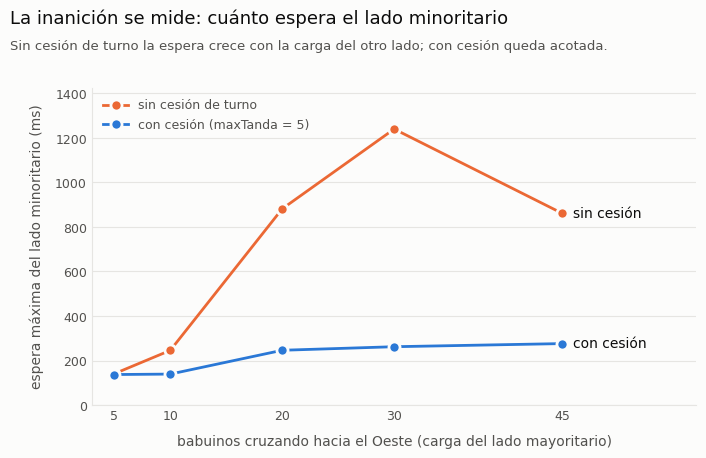

In [16]:
import matplotlib.pyplot as plt

TINTA       = "#0b0b0b"
TINTA_SUAVE = "#52514e"
SUPERFICIE  = "#fcfcfb"
GRILLA      = "#e6e5e2"
SIN_CESION  = "#eb6834"
CON_CESION  = "#2a78d6"

cargas = [f["carga"] for f in barrido]
sin_c  = [f["sin_cesion"] for f in barrido]
con_c  = [f["con_cesion"] for f in barrido]

fig, ax = plt.subplots(figsize=(7.8, 4.6))
fig.patch.set_facecolor(SUPERFICIE)
ax.set_facecolor(SUPERFICIE)

ax.grid(axis="y", color=GRILLA, linewidth=0.8)
ax.set_axisbelow(True)

for datos, color, etiqueta in ((sin_c, SIN_CESION, "sin cesión de turno"),
                               (con_c, CON_CESION, "con cesión (maxTanda = 5)")):
    ax.plot(cargas, datos, color=color, linewidth=2, marker="o", markersize=8,
            markerfacecolor=color, markeredgecolor=SUPERFICIE, markeredgewidth=2,
            label=etiqueta, zorder=3)

# Etiquetas directas al final de cada serie (identidad sin depender sólo del color).
ax.annotate("sin cesión", (cargas[-1], sin_c[-1]), xytext=(8, 0), textcoords="offset points",
            va="center", color=TINTA, fontsize=10)
ax.annotate("con cesión", (cargas[-1], con_c[-1]), xytext=(8, 0), textcoords="offset points",
            va="center", color=TINTA, fontsize=10)

ax.set_xlim(min(cargas) - 2, max(cargas) + 12)
ax.set_ylim(0, max(sin_c) * 1.15)
ax.set_xticks(cargas)
ax.set_xlabel("babuinos cruzando hacia el Oeste (carga del lado mayoritario)",
              color=TINTA_SUAVE, fontsize=10, labelpad=8)
ax.set_ylabel("espera máxima del lado minoritario (ms)", color=TINTA_SUAVE, fontsize=10, labelpad=8)
ax.tick_params(colors=TINTA_SUAVE, labelsize=9, length=0)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
for lado in ("left", "bottom"):
    ax.spines[lado].set_color(GRILLA)

ax.legend(frameon=False, loc="upper left", fontsize=9, labelcolor=TINTA_SUAVE)

fig.text(0.02, 0.97, "La inanición se mide: cuánto espera el lado minoritario",
         color=TINTA, fontsize=13, va="top")
fig.text(0.02, 0.905, "Sin cesión de turno la espera crece con la carga del otro lado; con cesión queda acotada.",
         color=TINTA_SUAVE, fontsize=9.5, va="top")
fig.subplots_adjust(top=0.80)
plt.show()

## 10. Conclusión

El programa cumple lo que pide el enunciado —**ningún babuino muere**— y lo hace por construcción, no por
suerte: los dos invariantes están escritos como una única condición de entrada dentro de un monitor, y todo
acceso a la cuerda pasa obligatoriamente por ahí.

### Resumen de los conceptos usados

| Concepto | Dónde aparece en este programa |
|---|---|
| **Hilo** | cada babuino (`Thread` + `Runnable`); más el hilo de la bitácora y el principal |
| **Memoria compartida** | el objeto `Cuerda`, visible por todos los hilos |
| **Sección crítica** | el cuerpo de `subirse` / `bajarse` |
| **Exclusión mutua** | `ReentrantLock` (cerrojo justo, FIFO) |
| **Monitor** | la clase `CuerdaSegura`: estado privado + cerrojo + condiciones |
| **Variables de condición** | `esperaCruce[ESTE]`, `esperaCruce[OESTE]`; `await()` / `signalAll()` |
| **Semántica Mesa** | la espera va en un `while`, nunca en un `if` |
| **Semáforo contador** | `Semaphore(5)` de la versión ingenua (necesario pero no suficiente) |
| **Espera pasiva** | `await()` y `sleep()`: el hilo suelta la CPU, no hay *busy waiting* |
| **Comunicación por mensajes** | `BlockingQueue` entre babuinos y bitácora (productor–consumidor) |
| **Píldora de veneno** | centinela `###FIN###` para cerrar el canal |
| **Variables atómicas / CAS** | `AtomicInteger`, `AtomicIntegerArray` en el `Verificador` |
| **Barrera de arranque** | `CountDownLatch` para largar a todos juntos |
| **Sincronización de terminación** | `Thread.join()` en el `main` |
| **Visibilidad entre hilos** | `volatile` en `esperaMs`; el `join()` como *happens-before* |
| **Condición de carrera** | lo que exhibe la versión ingenua |
| **Inanición y espera acotada** | `maxTanda` y la reserva de sentido en `bajarse` |
| **Ausencia de interbloqueo** | un único recurso y ninguna espera con el cerrojo tomado |

### Variantes posibles

- **Con `synchronized` / `wait()` / `notifyAll()`**: se puede escribir el mismo monitor con la sintaxis
  clásica de Java, pero habría **una sola cola de espera**, así que cada `notifyAll()` despertaría también a
  los del sentido contrario para que se vuelvan a dormir. Funciona, es menos preciso.
- **Sólo con semáforos**: es el ejercicio clásico de Downey (*The Little Book of Semaphores*). Hace falta un
  mutex para el contador de cada lado más un semáforo que represente "la cuerda está tomada por mi sentido",
  con el patrón del **torniquete** para el último que sale. Es más corto pero mucho más difícil de leer y de
  justificar: la lógica queda repartida en varios `acquire`/`release` en vez de en una sola condición.
- **Con `ReadWriteLock`**: el problema es isomorfo a lectores–escritores con dos clases de lectores mutuamente
  excluyentes, pero la biblioteca estándar no ofrece esa variante con límite de 5, así que igual habría que
  escribir el monitor.

### Cómo correrlo fuera del cuaderno

```
cd java_babuinos
javac -encoding UTF-8 -d build Babuinos.java
java -cp build Babuinos 6 5 5 42 1 0     # 6 al Oeste, 5 al Este, tandas de 5, semilla 42, con traza
java -cp build Babuinos 6 5 5 42 0 1     # la misma corrida con la cuerda ingenua: hay muertos
```